# SVD (surprise) — ranking at threshold `rating >= 4` (validation-first)

This notebook is **self-contained**: every piece of matrix construction, model
training, and evaluation logic lives inline below (no `src/` split). The only shared
import is the raw ratings loader `movielens.data.load_ratings`.

Explicit-feedback `surprise.SVD` (default hyperparameters + fixed seed) trained on
the rating matrix, on a chronological 80/10/10 split. It is evaluated as a **ranking**
model: each candidate item is scored by its SVD predicted rating, ranked descending,
and the top-10 are taken. The relevant set is held-out test items with `rating >= 4`.
Metrics are `precision@10` (primary), `NDCG@10`, `recall@10`, `hit-rate@10`.
There is **NO** popularity baseline in this notebook (the inline popularity
baseline is a separate shared step, plan t10). The trained model is logged to
MLflow under the **`test`** alias with registry name `svd-v1` and
`intent = svd-v1-gte4`.


In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import hashlib
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "movielens").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
from surprise import SVD, Dataset, Reader

from movielens.data import RAW_DIR, load_ratings

SEED = 42
K = 10
N_FACTORS = 100
N_EPOCHS = 20
BIASED = True
LR_ALL = 0.005
REG_ALL = 0.02
THRESHOLD = 4
EXPERIMENT = "svd"
REGISTRY_NAME = "svd-v1"
MLFLOW_URI = (ROOT / "mlflow" / "mlruns").as_uri()

plt.rcParams["figure.figsize"] = (8, 3.5)


In [2]:
def data_version_hash():
    digest = hashlib.sha1((RAW_DIR / "ratings.dat").read_bytes()).hexdigest()
    return digest[:12]


def git_sha():
    out = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return out.stdout.strip()


def precision_at_k(relevant, recommended, k=K):
    return float(np.mean([len(set(rec[:k]) & rel) / k for rel, rec in zip(relevant, recommended)]))


def recall_at_k(relevant, recommended, k=K):
    return float(
        np.mean([len(set(rec[:k]) & rel) / len(rel) if rel else 0.0 for rel, rec in zip(relevant, recommended)])
    )


def ndcg_at_k(relevant, recommended, k=K):
    vals = []
    for rel, rec in zip(relevant, recommended):
        dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(rec[:k]) if item in rel)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(rel))))
        vals.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(vals))


def hit_rate_at_k(relevant, recommended, k=K):
    return float(np.mean([1.0 if (set(rec[:k]) & rel) else 0.0 for rel, rec in zip(relevant, recommended)]))


## 1. EDA

Dataset shape, sparsity, the raw rating distribution, and the relevance
threshold (`rating >= 4` vs not). SVD consumes only the explicit rating matrix
(no tabular user/item features).


n_users: 6040
n_movies: 3706
n_ratings: 1000209
sparsity (observed / users x movies): 0.0447
relevant cells (rating >= 4): 575281
relevant ratio: 0.5752
imbalance (relevant / non-relevant): 1.35
full-matrix cells: 22384240
unobserved cells: 21384031


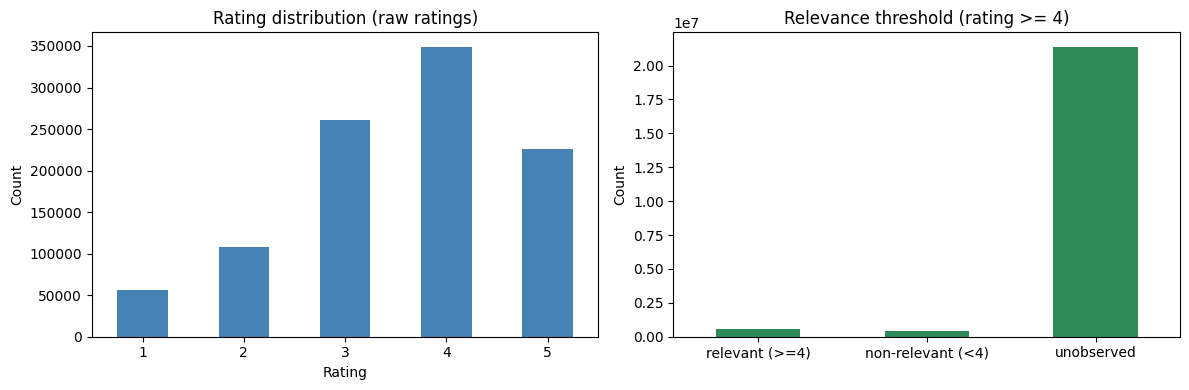

In [3]:
ratings = load_ratings()

n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)
sparsity = n_ratings / (n_users * n_movies)
n_positive = int((ratings["rating"] >= THRESHOLD).sum())

print("n_users:", n_users)
print("n_movies:", n_movies)
print("n_ratings:", n_ratings)
print("sparsity (observed / users x movies):", round(sparsity, 4))
print("relevant cells (rating >= 4):", n_positive)
print("relevant ratio:", round(n_positive / n_ratings, 4))
print("imbalance (relevant / non-relevant):", round(n_positive / (n_ratings - n_positive), 2))
print("full-matrix cells:", n_users * n_movies)
print("unobserved cells:", n_users * n_movies - n_ratings)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Rating distribution (raw ratings)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

signal = pd.Series(
    [n_positive, n_ratings - n_positive, n_users * n_movies - n_ratings],
    index=["relevant (>=4)", "non-relevant (<4)", "unobserved"],
)
signal.plot(kind="bar", ax=axes[1], color="seagreen", rot=0)
axes[1].set_title("Relevance threshold (rating >= 4)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 2. Chronological split + surprise trainset

Sort by `timestamp` (stable), split globally 80/10/10, and build the train-only
surprise `Trainset` from the train (earliest 80%) ratings.


In [4]:
user_ids = np.sort(ratings["user_id"].unique())
movie_ids = np.sort(ratings["movie_id"].unique())
user_index = {int(u): i for i, u in enumerate(user_ids)}
movie_index = {int(m): i for i, m in enumerate(movie_ids)}

df = ratings.sort_values(["timestamp", "user_id", "movie_id"], kind="stable").reset_index(drop=True)
n = len(df)
train_end = int(0.8 * n)
val_end = int(0.9 * n)
train = df.iloc[:train_end]
val = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

print("split sizes train/val/test:", len(train), len(val), len(test))
print("max train timestamp <= min val timestamp:",
      int(train["timestamp"].max()) <= int(val["timestamp"].min()))
print("max val timestamp <= min test timestamp:",
      int(val["timestamp"].max()) <= int(test["timestamp"].min()))

reader = Reader(rating_scale=(1, 5))
data = Dataset.load_from_df(train[["user_id", "movie_id", "rating"]], reader)
trainset = data.build_full_trainset()
print("trainset n_users:", trainset.n_users, "n_items:", trainset.n_items,
      "n_ratings:", trainset.n_ratings)


split sizes train/val/test: 800167 100021 100021
max train timestamp <= min val timestamp: True
max val timestamp <= min test timestamp: True


trainset n_users: 5400 n_items: 3662 n_ratings: 800167


## 3. Train surprise SVD

`n_factors=100, n_epochs=20, biased=True, lr_all=0.005, reg_all=0.02`
(surprise defaults) plus a fixed `random_state=42`. After fitting, the learned
factors/biases are mapped back to the full user/item id space; users/items absent
from the trainset (cold-start) are left with zero factors/bias, so their predicted
rating degrades to `global_mean + item_bias`.


In [5]:
model = SVD(
    n_factors=N_FACTORS,
    n_epochs=N_EPOCHS,
    biased=BIASED,
    lr_all=LR_ALL,
    reg_all=REG_ALL,
    random_state=SEED,
)
model.fit(trainset)

print("model config:", {
    "n_factors": model.n_factors,
    "n_epochs": model.n_epochs,
    "biased": model.biased,
    "lr_all": LR_ALL,
    "reg_all": REG_ALL,
    "random_state": SEED,
})
print("pu shape:", model.pu.shape, "qi shape:", model.qi.shape)

n_f = model.pu.shape[1]
pu_full = np.zeros((len(user_ids), n_f))
bu_full = np.zeros(len(user_ids))
qi_full = np.zeros((len(movie_ids), n_f))
bi_full = np.zeros(len(movie_ids))
for i, u in enumerate(user_ids):
    try:
        inner = trainset.to_inner_uid(int(u))
    except ValueError:
        continue
    pu_full[i] = model.pu[inner]
    bu_full[i] = model.bu[inner]
for j, m in enumerate(movie_ids):
    try:
        inner = trainset.to_inner_iid(int(m))
    except ValueError:
        continue
    qi_full[j] = model.qi[inner]
    bi_full[j] = model.bi[inner]
mu = model.trainset.global_mean

print("global mean (mu):", round(mu, 4))
print("users in trainset:", trainset.n_users, "of", len(user_ids),
      "-> cold-start users:", len(user_ids) - trainset.n_users)
print("items in trainset:", trainset.n_items, "of", len(movie_ids),
      "-> cold-start items:", len(movie_ids) - trainset.n_items)


model config: {'n_factors': 100, 'n_epochs': 20, 'biased': True, 'lr_all': 0.005, 'reg_all': 0.02, 'random_state': 42}
pu shape: (5400, 100) qi shape: (3662, 100)
global mean (mu): 3.5905
users in trainset: 5400 of 6040 -> cold-start users: 640
items in trainset: 3662 of 3706 -> cold-start items: 44


## 4. Evaluation — ranking (no baseline)

Per test user: `relevant` = held-out test items with `rating >= 4`; candidates = all
items not rated in train; score each candidate by its SVD predicted rating
(`mu + bu + bi + <pu, qi>`), rank descending, take top-10. Users with an empty
relevant set are excluded. Mean `precision@10` (primary), `NDCG@10`, `recall@10`,
`hit-rate@10`. No popularity baseline in this notebook.


In [6]:
test_users = sorted(test["user_id"].unique().tolist())
relevant = {
    u: set(test.loc[(test["user_id"] == u) & (test["rating"] >= THRESHOLD), "movie_id"])
    for u in test_users
}
train_rated = train.groupby("user_id")["movie_id"].apply(set).to_dict()

eval_users = [u for u in test_users if relevant[u]]
n_excluded = len(test_users) - len(eval_users)

uidx = np.array([user_index[u] for u in eval_users])
scores = mu + bu_full[uidx, None] + bi_full[None, :] + pu_full[uidx] @ qi_full.T

movie_arr = np.array(movie_ids)

model_recs = {}
for i, u in enumerate(eval_users):
    s = scores[i].copy()
    mask = np.array([int(m) in train_rated.get(u, set()) for m in movie_arr])
    s[mask] = -np.inf
    order = np.argsort(-s, kind="stable")
    model_recs[u] = movie_arr[order][:K].tolist()

rel_list = [relevant[u] for u in eval_users]
model_rec_list = [model_recs[u] for u in eval_users]

metrics = {
    "precision@10": precision_at_k(rel_list, model_rec_list),
    "ndcg@10": ndcg_at_k(rel_list, model_rec_list),
    "recall@10": recall_at_k(rel_list, model_rec_list),
    "hit-rate@10": hit_rate_at_k(rel_list, model_rec_list),
}

summary = pd.DataFrame(
    {
        "precision@10": [metrics["precision@10"]],
        "ndcg@10": [metrics["ndcg@10"]],
        "recall@10": [metrics["recall@10"]],
        "hit-rate@10": [metrics["hit-rate@10"]],
    },
    index=["svd model"],
)

print("test users (total):", len(test_users))
print("test users excluded (empty relevant set):", n_excluded)
print("test users evaluated:", len(eval_users))
print()
print(summary.round(6).to_string())


test users (total): 1209
test users excluded (empty relevant set): 21
test users evaluated: 1188

           precision@10   ndcg@10  recall@10  hit-rate@10
svd model       0.10303  0.111802   0.027465     0.463805


## Popularity baseline comparison (shared, model-independent)

Inline non-personalized baseline: top-10 movies by **training-time** rating count
(computed on the train fold only — no test-window leakage), excluding each user's
train-rated items. This is the same shared baseline applied across all four models
in plan `prove-all-models-gte4` (one set of numbers), evaluated on the identical
1188 test users with the identical relevant set (`rating >= 4`). The baseline is
NOT registered to MLflow and does not alter any existing run/version/alias.


In [ ]:
pop_count = train.groupby("movie_id").size()
pop_order = pop_count.reset_index(name="count").sort_values(
    ["count", "movie_id"], ascending=[False, True]
)["movie_id"].tolist()
pop_recs = {u: [m for m in pop_order if m not in train_rated.get(u, set())][:K] for u in eval_users}
pop_rec_list = [pop_recs[u] for u in eval_users]

pop_metrics = {
    "precision@10": precision_at_k(rel_list, pop_rec_list, K),
    "recall@10": recall_at_k(rel_list, pop_rec_list, K),
    "ndcg@10": ndcg_at_k(rel_list, pop_rec_list, K),
    "hit-rate@10": hit_rate_at_k(rel_list, pop_rec_list, K),
}

metric_order = ["precision@10", "recall@10", "ndcg@10", "hit-rate@10"]
cmp = pd.DataFrame({"model": metrics, "popularity": pop_metrics}).reindex(metric_order)
cmp["delta"] = cmp["model"] - cmp["popularity"]

print("popularity baseline (rating >= 4, training-time rating count, not registered):")
print(pd.DataFrame({"popularity": pop_metrics}).reindex(metric_order).round(6).to_string())
print()
print("model vs popularity (delta = model - popularity):")
print(cmp.round(6).to_string())
print()
verdict = "BEATS" if metrics["precision@10"] >= pop_metrics["precision@10"] else "LOSES"
print(f"verdict (precision@10): model {metrics['precision@10']:.6f} vs popularity {pop_metrics['precision@10']:.6f} -> {verdict}")


## 5. Log to MLflow (under the `test` alias)

Metrics, params, and the model artifact are logged; tags `code_version`,
`data_version`, and `intent` are set. The newly registered version is given the
**`test`** alias (never `Staging`/`Production`).


In [7]:
class SVDRecommender(mlflow.pyfunc.PythonModel):
    def __init__(self, pu, qi, bu, bi, mu, user_ids, movie_ids):
        self.pu = pu
        self.qi = qi
        self.bu = bu
        self.bi = bi
        self.mu = mu
        self.user_ids = user_ids
        self.movie_ids = movie_ids
        self.user_index = {int(u): i for i, u in enumerate(user_ids)}
        self.movie_index = {int(m): i for i, m in enumerate(movie_ids)}

    def predict(self, context, model_input):
        df = model_input
        ui = df["user_id"].map(self.user_index).to_numpy()
        mi = df["movie_id"].map(self.movie_index).to_numpy()
        return self.mu + self.bu[ui] + self.bi[mi] + (self.pu[ui] * self.qi[mi]).sum(axis=1)


mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()

params = dict(
    n_factors=N_FACTORS,
    n_epochs=N_EPOCHS,
    biased=BIASED,
    lr_all=LR_ALL,
    reg_all=REG_ALL,
    random_state=SEED,
)

metric_log = {k.replace("@", "_at_"): v for k, v in metrics.items()}

with mlflow.start_run() as active_run:
    run_id = active_run.info.run_id
    mlflow.log_params(params)
    mlflow.log_metrics(metric_log)
    mlflow.set_tags(
        {
            "code_version": git_sha(),
            "data_version": data_version_hash(),
            "intent": "svd-v1-gte4",
        }
    )
    info = mlflow.pyfunc.log_model(
        artifact_path="model",
        python_model=SVDRecommender(
            pu_full, qi_full, bu_full, bi_full, mu, user_ids, movie_ids
        ),
        registered_model_name=REGISTRY_NAME,
    )
    version = info.registered_model_version
    client.set_registered_model_alias(REGISTRY_NAME, "test", version)

print("run_id:", run_id)
print("registered version:", version)
print("test alias ->", client.get_model_version_by_alias(REGISTRY_NAME, "test").version)
print("code_version:", git_sha())
print("data_version:", data_version_hash())


C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
2026/10/19 00:21:38 INFO mlflow.tracking.fluent: Experiment with name 'svd' does not exist. Creating a new experiment.


2026/10/19 00:21:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/19 00:21:38 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


run_id: 8a37c962a7b64abdab814ed2c1e3fda7
registered version: 1
test alias -> 1
code_version: 172af8dd3b087c250ce2c8aaaa38104e548b3a39
data_version: 28770e0e10e2


Successfully registered model 'svd-v1'.
Created version '1' of model 'svd-v1'.
